# Sepsis Prediction from Clinical Data

In [1]:
    pip install --upgrade scikit-learn imbalanced-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.5/13.5 MB 86.7 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.2.2
    Uninstalling scikit-learn-1.2.2:
      Successfully uninstalled scikit-learn-1.2.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
category-encoders 2.7.0 requires scikit-learn<1.6.0,>=1.0.0, but you have scikit-learn 1.6.1 which is incompatible.
cesium 0.12.4 requires numpy<3.0,>=2.0, but you have numpy 1.26.4 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
from keras.models import Sequential
from keras.layers import LSTM
from imblearn.over_sampling import SMOTE
from keras.layers import Dense
from keras.regularizers import l2
from keras.layers import TimeDistributed, Bidirectional, BatchNormalization, Dropout, Input, Add, Masking
from keras import Model
import pdb
import pandas as pd
from keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical
from keras.models import load_model
from sklearn.metrics import confusion_matrix
from keras.callbacks import ModelCheckpoint
import glob
import sys
from sklearn.metrics import auc
import pickle
from sklearn.metrics import auc, f1_score, classification_report
from sklearn.metrics import confusion_matrix, auc
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from collections import Counter
import tensorflow as tf


2025-06-23 11:36:40.589551: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1750678600.846665      13 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1750678600.923862      13 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [3]:
import numpy as np
from keras.models import Sequential
from keras.layers import LSTM
from keras.layers import Dense
from keras.regularizers import l2
from keras.layers import TimeDistributed, Bidirectional, BatchNormalization, Dropout, Input, Add, Masking
from keras import Model
import pdb
import pandas as pd
from keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical
from keras.models import load_model
from sklearn.metrics import confusion_matrix
from keras.callbacks import ModelCheckpoint
import glob
import sys
from sklearn.metrics import auc, f1_score, classification_report
import pickle
from imblearn.over_sampling import SMOTE
from collections import Counter
import tensorflow as tf

In [4]:
import pandas as pd
import numpy as np
import pdb
import os
import shutil

In [5]:
#This is a time series model for the prediction of sepsis 
import pandas as pd 
df = pd.read_csv("/kaggle/input/my-dataset/Dataset.csv")
print(df.head())

   Unnamed: 0  Hour    HR  O2Sat  Temp    SBP   MAP   DBP  Resp  EtCO2  ...  \
0           0     0   NaN    NaN   NaN    NaN   NaN   NaN   NaN    NaN  ...   
1           1     1  65.0  100.0   NaN    NaN  72.0   NaN  16.5    NaN  ...   
2           2     2  78.0  100.0   NaN    NaN  42.5   NaN   NaN    NaN  ...   
3           3     3  73.0  100.0   NaN    NaN   NaN   NaN  17.0    NaN  ...   
4           4     4  70.0  100.0   NaN  129.0  74.0  69.0  14.0    NaN  ...   

   Fibrinogen  Platelets    Age  Gender  Unit1  Unit2  HospAdmTime  ICULOS  \
0         NaN        NaN  68.54       0    NaN    NaN        -0.02       1   
1         NaN        NaN  68.54       0    NaN    NaN        -0.02       2   
2         NaN        NaN  68.54       0    NaN    NaN        -0.02       3   
3         NaN        NaN  68.54       0    NaN    NaN        -0.02       4   
4         NaN      330.0  68.54       0    NaN    NaN        -0.02       5   

   SepsisLabel  Patient_ID  
0            0       17072 

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


In [6]:
df = df.drop(columns=['Unnamed: 0'])

In [7]:
df = df.drop(columns=['Hour'])

In [8]:
#get the percentage missing for each column
print('Percentage Missing:')
print(df.isna().sum()/len(df))

#columns to drop
#drop Unit2 because Unit1 and Unit2 are mutually exclusive
#drop ICULOS as it's basically just an index
cols_to_drop = ['Unit2', 'ICULOS']
df = df.drop(cols_to_drop, axis=1)

#columns with < 15% missing data, and continuous data. these will be retained as time series
cols_cont = ['HR', 'MAP', 'O2Sat', 'SBP', 'Resp']

#columns with continuous data and > 15% missing data
cols_to_bin = ['Unit1', 'Gender', 'HospAdmTime', 'Age', 'DBP', 'Temp', 'Glucose', 'Potassium', 'Hct', 'FiO2', 'Hgb', 'pH', 'BUN', 'WBC', 'Magnesium', 'Creatinine', 'Platelets', 'Calcium', 'PaCO2', 'BaseExcess', 'Chloride', 'HCO3', 'Phosphate', 'EtCO2', 'SaO2', 'PTT', 'Lactate', 'AST', 'Alkalinephos', 'Bilirubin_total', 'TroponinI', 'Fibrinogen', 'Bilirubin_direct']

Percentage Missing:
HR                  0.098826
O2Sat               0.130611
Temp                0.661627
SBP                 0.145770
MAP                 0.124513
DBP                 0.313459
Resp                0.153546
EtCO2               0.962868
BaseExcess          0.945790
HCO3                0.958106
FiO2                0.916658
pH                  0.930697
PaCO2               0.944401
SaO2                0.965494
AST                 0.983776
BUN                 0.931344
Alkalinephos        0.983932
Calcium             0.941161
Chloride            0.954603
Creatinine          0.939044
Bilirubin_direct    0.998074
Glucose             0.828943
Lactate             0.973299
Magnesium           0.936896
Phosphate           0.959863
Potassium           0.906891
Bilirubin_total     0.985092
TroponinI           0.990477
Hct                 0.911460
Hgb                 0.926176
PTT                 0.970559
WBC                 0.935932
Fibrinogen          0.993402
Platelets           0.9

In [9]:
patients_training_data = df['Patient_ID'].unique()
np.random.shuffle(patients_training_data)
patients_training_data = patients_training_data[0:-6000]

df_mean_std = df[df['Patient_ID'].isin(patients_training_data)].describe().loc[['mean', 'std']]
df_mean_std.to_pickle('mean_std_scaling.pkl')

In [10]:
print('Number of positive training examples:')
sum(df[df['Patient_ID'].isin(patients_training_data)]['SepsisLabel']==1)

Number of positive training examples:


23701

In [11]:
save_count = 0
windowed_df_list = []

grouped_by_patient = df.groupby('Patient_ID')

for Patient_ID, group in grouped_by_patient:
    group = group.reset_index(drop=True)

    # Fill missing values for continuous variables
    for col in ['HR', 'MAP', 'O2Sat', 'SBP', 'Resp']:
        group[col] = group[col].bfill().ffill()

    # Drop rows where any of these are still NaN
    group = group.dropna(subset=['HR', 'MAP', 'O2Sat', 'SBP', 'Resp'])

    # Standardize continuous variables
    for col in ['HR', 'MAP', 'O2Sat', 'SBP', 'Resp']:
        group[col] = (group[col] - df_mean_std[col]['mean']) / df_mean_std[col]['std']

    windowed_data = []
    N = len(group)
    win_len = 10
    pred_len = 1
    i = 0

    while i + win_len + pred_len <= N:
        tmp_data = group.iloc[i:i+win_len]
        tmp_label_data = group.iloc[i+win_len:i+win_len+pred_len]
        tmp_label = int(tmp_label_data['SepsisLabel'].any())

        X_cont = tmp_data[cols_cont].values

        if np.isnan(X_cont).any():
            i += 1
            continue

        # Prepare binned features
        X_binned_dict = {}
        for col_to_bin in cols_to_bin:
            val = tmp_data[col_to_bin].median()
            if col_to_bin not in ['Gender', 'Unit1']:
                val = (val - df_mean_std[col_to_bin]['mean']) / df_mean_std[col_to_bin]['std']
            X_binned_dict[col_to_bin] = val

        # Append full window dict
        X_binned_dict.update({
            'X_cont': X_cont,
            'label': tmp_label,
            'Patient_ID': Patient_ID
        })

        windowed_data.append(X_binned_dict)
        i += 1

    # Save this patient's data
    if windowed_data:
        windowed_df_list.append(pd.DataFrame(windowed_data))

    # Periodic saving
    if (int(str(Patient_ID)[-5:]) % 500) == 0:
        print(f'Patient_ID {int(str(Patient_ID)[-5:])}')

        if windowed_df_list:
            windowed_df = pd.concat(windowed_df_list, ignore_index=True)
            train = windowed_df[windowed_df['Patient_ID'].isin(patients_training_data)].drop('Patient_ID', axis=1)
            test = windowed_df[~windowed_df['Patient_ID'].isin(patients_training_data)].drop('Patient_ID', axis=1)

            os.makedirs('feats', exist_ok=True)
            train.to_pickle(f'feats/train_{save_count}.pkl')
            test.to_pickle(f'feats/test_{save_count}.pkl')

            windowed_df_list = []
            save_count += 1

# Final save
if windowed_df_list:
    windowed_df = pd.concat(windowed_df_list, ignore_index=True)
    train = windowed_df[windowed_df['Patient_ID'].isin(patients_training_data)].drop('Patient_ID', axis=1)
    test = windowed_df[~windowed_df['Patient_ID'].isin(patients_training_data)].drop('Patient_ID', axis=1)

    os.makedirs('feats', exist_ok=True)
    train.to_pickle(f'feats/train_{save_count}.pkl')
    test.to_pickle(f'feats/test_{save_count}.pkl')

Patient_ID 500
Patient_ID 1000
Patient_ID 1500
Patient_ID 2000
Patient_ID 2500
Patient_ID 3000
Patient_ID 3500
Patient_ID 4000
Patient_ID 4500
Patient_ID 5000
Patient_ID 5500
Patient_ID 6000
Patient_ID 6500
Patient_ID 7000
Patient_ID 7500
Patient_ID 8000
Patient_ID 8500
Patient_ID 9000
Patient_ID 9500
Patient_ID 10000
Patient_ID 10500
Patient_ID 11000
Patient_ID 11500
Patient_ID 12000
Patient_ID 12500
Patient_ID 13000
Patient_ID 13500
Patient_ID 14000
Patient_ID 14500
Patient_ID 15000
Patient_ID 15500
Patient_ID 16000
Patient_ID 16500
Patient_ID 17000
Patient_ID 17500
Patient_ID 18000
Patient_ID 18500
Patient_ID 19000
Patient_ID 19500
Patient_ID 20000
Patient_ID 20500
Patient_ID 500
Patient_ID 1000
Patient_ID 1500
Patient_ID 2000
Patient_ID 2500
Patient_ID 3000
Patient_ID 3500
Patient_ID 4000
Patient_ID 4500
Patient_ID 5000
Patient_ID 5500
Patient_ID 6000
Patient_ID 6500
Patient_ID 7000
Patient_ID 7500
Patient_ID 8000
Patient_ID 8500
Patient_ID 9000
Patient_ID 9500
Patient_ID 10000
Pat

In [12]:
num_train_patients = len(patients_training_data)
num_total_patients = df['Patient_ID'].nunique()
train_percent = (num_train_patients / num_total_patients) * 100
print(train_percent)

85.12495041650139


In [13]:
shutil.make_archive('sepsis_feats', 'zip', 'feats')

'/kaggle/working/sepsis_feats.zip'

In [14]:
#Over here we look at feature correlations and removes any features
# that are highly correlated 

try:
    if os.path.exists('plots'):
        shutil.rmtree('plots')
    os.makedirs('plots')
except Exception as e: 
    print(e)

In [15]:
#Load the data 
#load the training data
train_files = glob.glob('/kaggle/working/feats/train_*.pkl')
train = []
for train_file in train_files:
    train.append(pd.read_pickle(train_file))

train = pd.concat(train)

#load the test data
test_files = glob.glob('/kaggle/working/feats/test_*.pkl')
test = []
for test_file in test_files:
    test.append(pd.read_pickle(test_file))

test = pd.concat(test)

/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


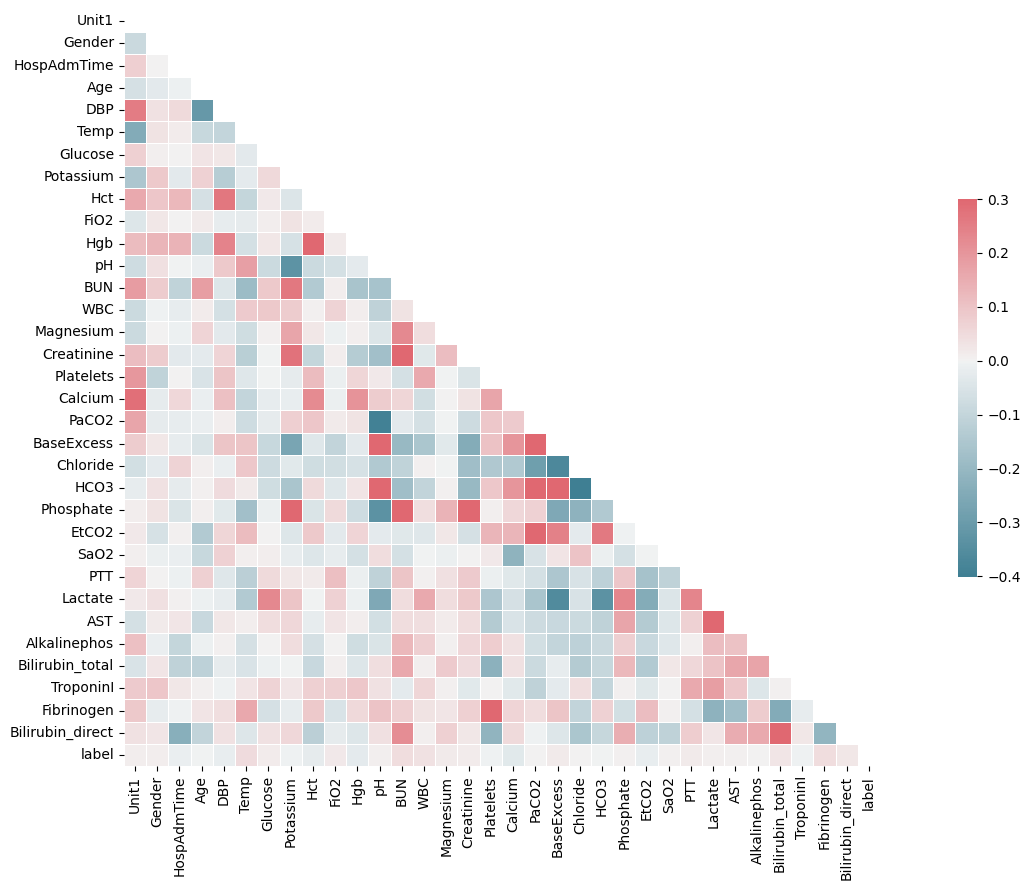

Columns in file: Index(['Unit1', 'Gender', 'HospAdmTime', 'Age', 'DBP', 'Temp', 'Glucose',
       'Potassium', 'Hct', 'FiO2', 'Hgb', 'pH', 'BUN', 'WBC', 'Magnesium',
       'Creatinine', 'Platelets', 'Calcium', 'PaCO2', 'BaseExcess', 'Chloride',
       'HCO3', 'Phosphate', 'EtCO2', 'SaO2', 'PTT', 'Lactate', 'AST',
       'Alkalinephos', 'Bilirubin_total', 'TroponinI', 'Fibrinogen',
       'Bilirubin_direct', 'X_cont', 'label'],
      dtype='object')
Data types:
Unit1               float64
Gender              float64
HospAdmTime         float64
Age                 float64
DBP                 float64
Temp                float64
Glucose             float64
Potassium           float64
Hct                 float64
FiO2                float64
Hgb                 float64
pH                  float64
BUN                 float64
WBC                 float64
Magnesium           float64
Creatinine          float64
Platelets           float64
Calcium             float64
PaCO2               float64
Ba

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pan

In [16]:
# Calculate correlation on scalar columns only (X_cont is ignored automatically)
import seaborn as sns
corr = train.drop(columns=['X_cont']).corr()

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))
cmap = sns.diverging_palette(220, 10, as_cmap=True)

# Plot heatmap
plt.figure(figsize=(16,9))
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=.3, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})
plt.tight_layout()
plt.savefig('plots/heatmap.png', dpi=250)
plt.show()

# Save data
train.to_pickle('train.pkl')
test.to_pickle('test.pkl')

# Check basic info about the file
import json  # Add this at the top if not already present

# Convert 'X_cont' to JSON string for storage
new_data_to_save = test.copy()
new_data_to_save['X_cont'] = new_data_to_save['X_cont'].apply(lambda x: json.dumps(x.tolist()))

# Save to CSV
new_data_to_save.to_csv('test.csv', index=False)

# Info about the saved DataFrame
print(f"Columns in file: {new_data_to_save.columns}")
print(f"Data types:\n{new_data_to_save.dtypes}")
print(f"Missing values:\n{new_data_to_save.isnull().sum()}")
print(f"Shape of data: {new_data_to_save.shape}")
print(f"First few rows:\n{new_data_to_save.head()}")

# Check the first few rows
print(f"First few rows:\n{test.head()}")
print("Test dataset columns:")
print(test.columns.tolist())

# Model training

In [17]:

BATCH_SIZE = 64
INPUT_SEQ_LEN_MODEL1 = 10
INPUT_NUM_CH_MODEL1 = 5
INPUT_FEATS_MODEL2 = 33

In [18]:
def focal_loss(alpha=0.90, gamma=2.0):
    """
    Focal Loss implementation specifically for highly imbalanced datasets
    Alpha: weight for rare class (higher = more focus on minority class)
    Gamma: focusing parameter (higher = more focus on hard examples)
    """
    def focal_loss_fixed(y_true, y_pred):
        # Clip predictions to prevent NaN values
        y_pred = tf.clip_by_value(y_pred, tf.keras.backend.epsilon(), 1 - tf.keras.backend.epsilon())
        
        # Calculate cross entropy
        ce = -y_true * tf.math.log(y_pred)
        
        # Calculate p_t
        p_t = tf.where(tf.equal(y_true, 1), y_pred, 1 - y_pred)
        
        # Calculate alpha_t
        alpha_t = tf.ones_like(y_true) * alpha
        alpha_t = tf.where(tf.equal(y_true, 1), alpha_t, 1 - alpha_t)
        
        # Calculate focal weight
        focal_weight = alpha_t * tf.pow((1 - p_t), gamma)
        
        # Calculate focal loss
        fl = focal_weight * ce
        
        return tf.reduce_mean(fl)
    
    return focal_loss_fixed

In [19]:
def apply_time_aware_smote(X_cont, X_cat, y, target_ratio=0.3):
    """
    Apply SMOTE while preserving temporal structure for time series data
    """
    print(f"Original distribution: {Counter(y)}")
    
    # Flatten continuous features for SMOTE
    n_samples, seq_len, n_features = X_cont.shape
    X_cont_flat = X_cont.reshape(n_samples, -1)
    
    # Combine continuous and categorical features
    X_combined = np.concatenate([X_cont_flat, X_cat], axis=1)
    
    # Apply SMOTE
    smote = SMOTE(sampling_strategy=target_ratio, random_state=42, k_neighbors=3)
    X_resampled, y_resampled = smote.fit_resample(X_combined, y)
    
    # Separate back into continuous and categorical
    cont_features = seq_len * n_features
    X_cont_resampled = X_resampled[:, :cont_features].reshape(-1, seq_len, n_features)
    X_cat_resampled = X_resampled[:, cont_features:]
    
    print(f"After SMOTE distribution: {Counter(y_resampled)}")
    
    return X_cont_resampled, X_cat_resampled, y_resampled

def apply_intelligent_undersampling(X_cont, X_cat, y, target_ratio=0.4):
    """
    Intelligent undersampling that preserves diversity in majority class
    """
    print(f"Before undersampling: {Counter(y)}")
    
    # Get indices of majority and minority classes
    minority_idx = np.where(y == 1)[0]
    majority_idx = np.where(y == 0)[0]
    
    # Calculate target number of majority samples
    target_majority = int(len(minority_idx) / target_ratio - len(minority_idx))
    target_majority = min(target_majority, len(majority_idx))
    
    # Random undersampling of majority class
    np.random.seed(42)
    selected_majority_idx = np.random.choice(majority_idx, size=target_majority, replace=False)
    
    # Combine indices
    final_idx = np.concatenate([minority_idx, selected_majority_idx])
    np.random.shuffle(final_idx)
    
    print(f"After undersampling: {Counter(y[final_idx])}")
    
    return X_cont[final_idx], X_cat[final_idx], y[final_idx]

In [20]:
def find_optimal_f1_threshold(predictions, true, filename):
    """
    Enhanced ROC analysis with F1 score optimization
    """
    predictions = predictions.flatten()
    true = true.flatten()

    thresh_vals = np.linspace(0.05, 0.95, 100)  # More granular threshold search
    results = []

    for thresh in thresh_vals:
        tmp_predictions = (predictions > thresh).astype(int)
        tn, fp, fn, tp = confusion_matrix(true, tmp_predictions).ravel()

        tpr = tp / (tp + fn) if (tp + fn) != 0 else 0  # Recall / Sensitivity
        fpr = fp / (tn + fp) if (tn + fp) != 0 else 0
        acc = (tp + tn) / (tn + fp + fn + tp)

        # Manual F1 Score calculation
        precision = tp / (tp + fp) if (tp + fp) != 0 else 0
        recall = tpr
        f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) != 0 else 0

        tmp_dict = {
            'acc': acc,
            'tpr': tpr,
            'fpr': fpr,
            'f1': f1,
            'precision': precision,
            'recall': recall,
            'thresh': thresh
        }
        results.append(tmp_dict)

    results = pd.DataFrame(results)
    results = results.sort_values(by='thresh', ascending=False)

    # AUC
    results_sorted_fpr = results.sort_values(by='fpr')
    AUC = auc(results_sorted_fpr['fpr'].values, results_sorted_fpr['tpr'].values)

    # ROC plot
    plt.figure(figsize=(15, 5))
    
    # ROC Curve
    plt.subplot(1, 3, 1)
    plt.plot(results_sorted_fpr['fpr'], results_sorted_fpr['tpr'], 'b-', linewidth=2)
    plt.xlabel('FPR')
    plt.ylabel('TPR')
    plt.title('ROC Curve\nAUC=%.3f' % AUC)
    plt.grid(True, alpha=0.3)
    
    # F1 Score vs Threshold
    plt.subplot(1, 3, 2)
    plt.plot(results['thresh'], results['f1'], 'g-', linewidth=2)
    plt.xlabel('Threshold')
    plt.ylabel('F1 Score')
    plt.title('F1 Score vs Threshold')
    plt.grid(True, alpha=0.3)
    
    # Precision-Recall vs Threshold
    plt.subplot(1, 3, 3)
    plt.plot(results['thresh'], results['precision'], 'r-', linewidth=2, label='Precision')
    plt.plot(results['thresh'], results['recall'], 'b-', linewidth=2, label='Recall')
    plt.xlabel('Threshold')
    plt.ylabel('Score')
    plt.title('Precision & Recall vs Threshold')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('plots/enhanced_metrics_%s.png' % filename, dpi=250)
    plt.show()

    # Best threshold by F1 score
    results = results.sort_values(by='f1', ascending=False)
    final_thresh = results.head(1)['thresh'].values[0]
    best_f1 = results.head(1)['f1'].values[0]
    
    print(f"Optimal threshold for F1: {final_thresh:.3f}")
    print(f"Best F1 score: {best_f1:.3f}")

    return results, final_thresh, best_f1

In [21]:
# Load the training data
train = pd.read_pickle('/kaggle/working/train.pkl').reset_index(drop=True)

# Define the validation set as 20% of the training set
N = len(train)
train = train.sample(frac=1, random_state=42).reset_index(drop=True)
val = train[:int(N*0.2)]
train = train[int(N*0.2):]

# Separate out the training data
y_train_original = np.asarray(list(train['label']))
X_train_cont_original = np.asarray(list(train['X_cont'].values))
X_train_cat_original = train.drop(['X_cont', 'label'], axis=1)

# For the mask layer, any NaN values need to be replaced by a unique value
X_train_cat_original[X_train_cat_original.isna()] = np.pi
X_train_cat_original = np.asarray(list(X_train_cat_original.values))

# Separate out the validation data
y_val = np.asarray(list(val['label']))
y_val = to_categorical(y_val)
X_val_cont = np.asarray(list(val['X_cont'].values))
X_val_cat = val.drop(['X_cont', 'label'], axis=1)

# Replace NaN with pi
X_val_cat[X_val_cat.isna()] = np.pi
X_val_cat = np.asarray(list(X_val_cat.values))

# Load the test data
test = pd.read_pickle('test.pkl')
y_test = np.asarray(list(test['label']))
y_test_categorical = to_categorical(y_test)
X_test_cont = np.asarray(list(test['X_cont'].values))
X_test_cat = test.drop(['X_cont', 'label'], axis=1)

# Replace NaN with pi
X_test_cat[X_test_cat.isna()] = np.pi
X_test_cat = np.asarray(list(X_test_cat.values))

print("Original class distribution in training:")
print(f"No sepsis: {np.sum(y_train_original == 0)}")
print(f"Sepsis: {np.sum(y_train_original == 1)}")
print(f"Imbalance ratio: {np.sum(y_train_original == 0) / np.sum(y_train_original == 1):.2f}:1")

Original class distribution in training:
No sepsis: 762601
Sepsis: 14150
Imbalance ratio: 53.89:1


In [22]:
X_train_cont_under, X_train_cat_under, y_train_under = apply_intelligent_undersampling(
    X_train_cont_original, X_train_cat_original, y_train_original, target_ratio=0.25)

Before undersampling: Counter({0: 762601, 1: 14150})
After undersampling: Counter({0: 42450, 1: 14150})


In [23]:



X_train_cont, X_train_cat, y_train = apply_time_aware_smote(
    X_train_cont_under, X_train_cat_under, y_train_under, target_ratio=0.4)

Original distribution: Counter({0: 42450, 1: 14150})
After SMOTE distribution: Counter({0: 42450, 1: 16980})


In [24]:
# Convert to categorical for training
y_train = to_categorical(y_train)

In [25]:
print("\nFinal training distribution after combined sampling:")
print(f"Total samples: {len(y_train)}")
print(f"Class 0: {np.sum(y_train[:, 0])}")
print(f"Class 1: {np.sum(y_train[:, 1])}")


Final training distribution after combined sampling:
Total samples: 59430
Class 0: 42450.0
Class 1: 16980.0


In [26]:
count_class_0 = np.sum(y_train[:,0].astype(int)==1)
count_class_1 = np.sum(y_train[:, 1].astype(int) == 1)
max_class_counts = np.max((count_class_0, count_class_1))

# More balanced class weights after sampling
class_weights = {
    0: max_class_counts/count_class_0, 
    1: max_class_counts/count_class_1
}

print('Refined class weights -- no sepsis: {:.4f}, sepsis: {:.4f}'.format(
    class_weights[0], class_weights[1]))

Refined class weights -- no sepsis: 1.0000, sepsis: 2.5000


In [27]:
# Enhanced model with better regularization and dropout
input1 = Input(shape=(INPUT_SEQ_LEN_MODEL1, INPUT_NUM_CH_MODEL1))
model1 = Bidirectional(LSTM(128, kernel_regularizer=l2(0.001), 
                           return_sequences=True, dropout=0.2, 
                           recurrent_dropout=0.2))(input1)
model1 = Bidirectional(LSTM(64, kernel_regularizer=l2(0.001),
                           dropout=0.2, recurrent_dropout=0.2))(model1)
model1 = Dense(50, kernel_regularizer=l2(0.001), activation='relu')(model1)
model1 = BatchNormalization()(model1)
model1 = Dropout(0.3)(model1)
model1 = Dense(25, kernel_regularizer=l2(0.001), activation='relu')(model1)
model1 = BatchNormalization()(model1)

input2 = Input(shape=(INPUT_FEATS_MODEL2,))
model2 = Masking(mask_value=np.pi)(input2)
model2 = Dense(40, kernel_regularizer=l2(0.001), activation='relu')(model2)
model2 = BatchNormalization()(model2)
model2 = Dropout(0.3)(model2)
model2 = Dense(25, kernel_regularizer=l2(0.001), activation='relu')(model2)
model2 = BatchNormalization()(model2)

model_add = Add()([model1, model2])
model_add = Dropout(0.2)(model_add)
output = Dense(2, kernel_regularizer=l2(0.001), activation='softmax')(model_add)

model = Model(inputs=[input1, input2], outputs=output)

# Compile with Focal Loss for better imbalanced data handling
model.compile(loss=focal_loss(alpha=0.75, gamma=2.0), optimizer='adam')
print(model.summary())

2025-06-23 12:29:31.335279: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 10, 5)          │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ bidirectional             │ (None, 10, 256)        │        137,216 │ input_layer[0][0]      │
│ (Bidirectional)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ input_layer_1             │ (None, 33)             │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ bidirectional_1           │ (None, 128)            │        164,352 │ bidirectional[0][0]    │
│ (Bidirectional)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ masking (Masking)         │ (None, 33)             │              0 │ input_layer_1[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ not_equal (NotEqual)      │ (None, 33)             │              0 │ input_layer_1[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense (Dense)             │ (None, 50)             │          6,450 │ bidirectional_1[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_2 (Dense)           │ (None, 40)             │          1,360 │ masking[0][0]          │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ any (Any)                 │ (None)                 │              0 │ not_equal[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization       │ (None, 50)             │            200 │ dense[0][0]            │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_2     │ (None, 40)             │            160 │ dense_2[0][0],         │
│ (BatchNormalization)      │                        │                │ any[0][0]              │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout (Dropout)         │ (None, 50)             │              0 │ batch_normalization[0… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_1 (Dropout)       │ (None, 40)             │              0 │ batch_normalization_2… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_1 (Dense)           │ (None, 25)             │          1,275 │ dropout[0][0]          │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_3 (Dense)           │ (None, 25)             │          1,025 │ dropout_1[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_1     │ (None, 25)             │            100 │ dense_1[0][0]          │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_3

 Total params: 312,290 (1.19 MB)

 Trainable params: 312,010 (1.19 MB)

 Non-trainable params: 280 (1.09 KB)

None


In [28]:
checkpoint = ModelCheckpoint('best_model_enhanced.keras', monitor='val_loss', 
                            verbose=1, save_best_only=True, mode='auto')
earlystop = EarlyStopping(monitor='val_loss', min_delta=0.001, 
                         patience=10, restore_best_weights=True)

# Train the model
history = model.fit([X_train_cont, X_train_cat],
                    y_train,
                    batch_size=BATCH_SIZE,
                    epochs=100,
                    validation_data=([X_val_cont, X_val_cat], y_val),
                    callbacks=[earlystop, checkpoint],
                    class_weight=class_weights,  # Still use some class weights with focal loss
                    verbose=1)


pickle.dump(history, open('history_enhanced.pkl', 'wb'))

Epoch 1/100
929/929 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.5112
Epoch 1: val_loss improved from inf to 0.10595, saving model to best_model_enhanced.keras
929/929 ━━━━━━━━━━━━━━━━━━━━ 107s 88ms/step - loss: 0.5109 - val_loss: 0.1059
Epoch 2/100
928/929 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.1255
Epoch 2: val_loss improved from 0.10595 to 0.04931, saving model to best_model_enhanced.keras
929/929 ━━━━━━━━━━━━━━━━━━━━ 79s 85ms/step - loss: 0.1255 - val_loss: 0.0493
Epoch 3/100
928/929 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.0853
Epoch 3: val_loss improved from 0.04931 to 0.04335, saving model to best_model_enhanced.keras
929/929 ━━━━━━━━━━━━━━━━━━━━ 79s 86ms/step - loss: 0.0853 - val_loss: 0.0434
Epoch 4/100
929/929 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.0774
Epoch 4: val_loss improved from 0.04335 to 0.02890, saving model to best_model_enhanced.keras
929/929 ━━━━━━━━━━━━━━━━━━━━ 86s 92ms/step - loss: 0.0774 - val_loss: 0.0289
Epoch 5/100
929/929 ━━━━━━━━━━━━━━━━━━━━ 0s

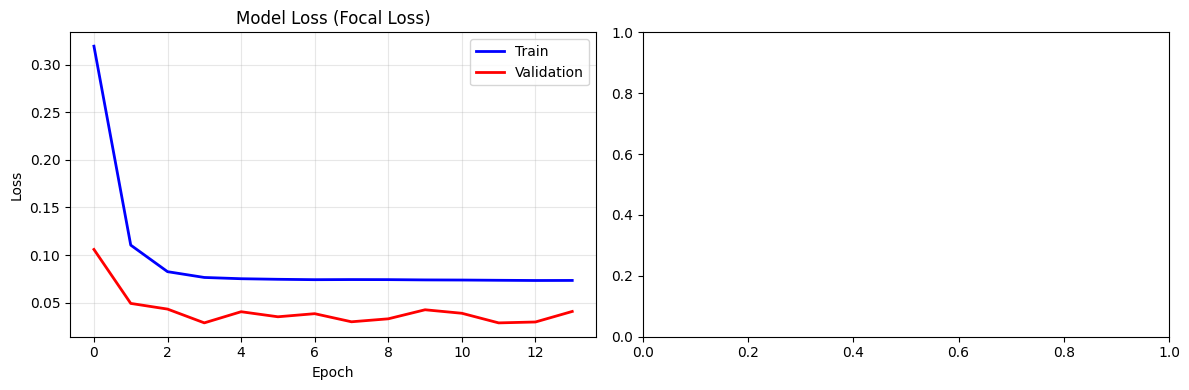

In [29]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], 'b-', linewidth=2, label='Train')
plt.plot(history.history['val_loss'], 'r-', linewidth=2, label='Validation')
plt.title('Model Loss (Focal Loss)')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
# Plot learning rate if available
if 'lr' in history.history:
    plt.plot(history.history['lr'], 'g-', linewidth=2)
    plt.title('Learning Rate')
    plt.ylabel('Learning Rate')
    plt.xlabel('Epoch')
    plt.yscale('log')
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('plots/enhanced_training.png', dpi=250)
plt.show()

=== VALIDATION SET EVALUATION ===
6069/6069 ━━━━━━━━━━━━━━━━━━━━ 59s 9ms/step


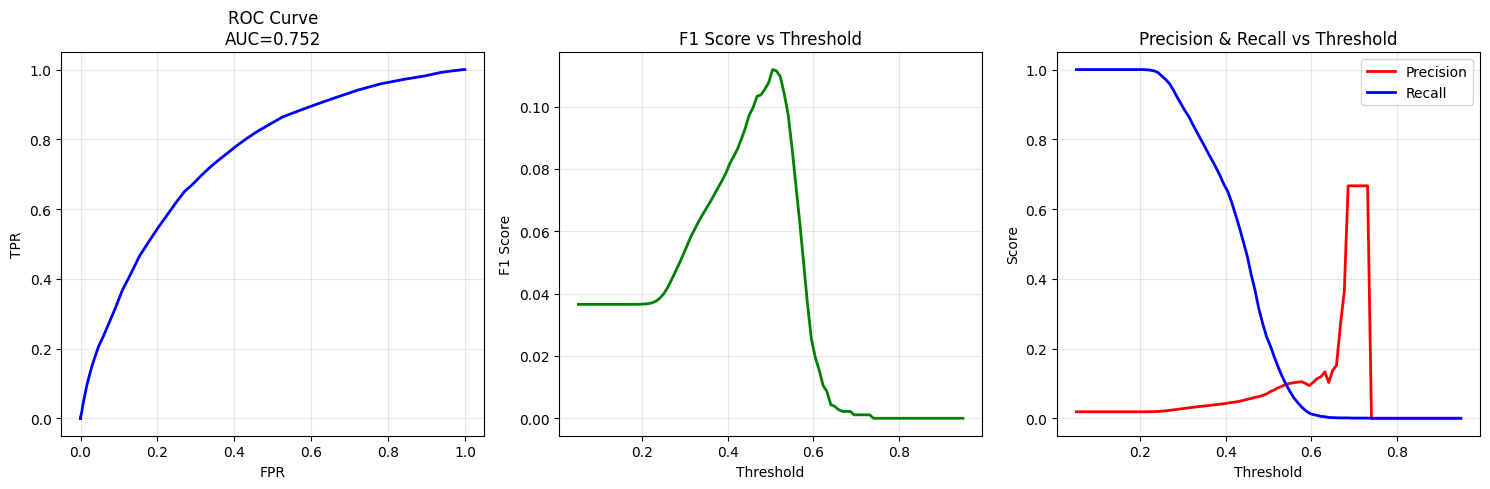

Optimal threshold for F1: 0.505
Best F1 score: 0.112

Validation Classification Report (Optimal F1 Threshold):
              precision    recall  f1-score   support

           0       0.98      0.95      0.97    190572
           1       0.08      0.21      0.11      3615

    accuracy                           0.94    194187
   macro avg       0.53      0.58      0.54    194187
weighted avg       0.97      0.94      0.95    194187



In [30]:
print("=== VALIDATION SET EVALUATION ===")
predictions_val = model.predict([X_val_cont, X_val_cat])

results_df_val, thresh_final_val, best_f1_val = find_optimal_f1_threshold(
    predictions_val[:,1].flatten(), y_val[:,1].flatten(), 'validation')

# Generate classification report for validation
y_val_pred_optimal = (predictions_val[:,1] >= thresh_final_val).astype(int)
print("\nValidation Classification Report (Optimal F1 Threshold):")
print(classification_report(y_val[:,1].astype(int), y_val_pred_optimal))


=== TEST SET EVALUATION ===
5261/5261 ━━━━━━━━━━━━━━━━━━━━ 47s 9ms/step


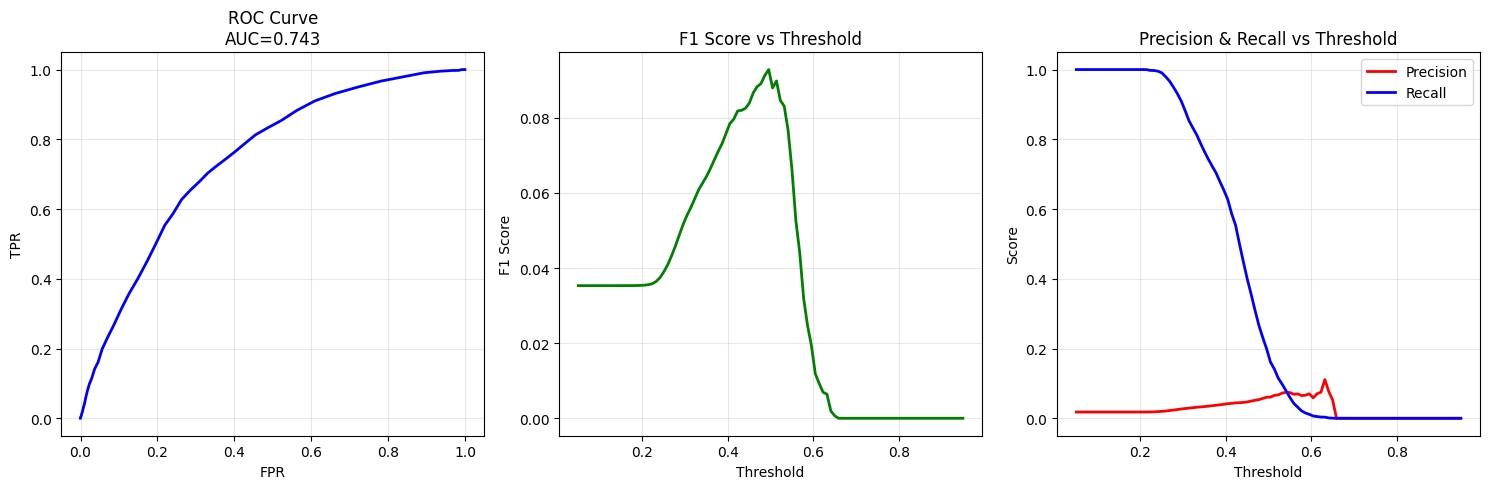

Optimal threshold for F1: 0.495
Best F1 score: 0.093

Test Classification Report (Optimal F1 Threshold):
              precision    recall  f1-score   support

           0       0.98      0.94      0.96    165314
           1       0.06      0.20      0.09      3026

    accuracy                           0.93    168340
   macro avg       0.52      0.57      0.53    168340
weighted avg       0.97      0.93      0.95    168340



In [31]:
print("\n=== TEST SET EVALUATION ===")
predictions_test = model.predict([X_test_cont, X_test_cat])

results_df_test, thresh_final_test, best_f1_test = find_optimal_f1_threshold(
    predictions_test[:,1].flatten(), y_test.flatten(), 'test')

# Generate classification report for test set
y_test_pred_optimal = (predictions_test[:,1] >= thresh_final_test).astype(int)
print("\nTest Classification Report (Optimal F1 Threshold):")
print(classification_report(y_test, y_test_pred_optimal))

In [32]:
print("\n" + "="*60)
print("SUMMARY OF IMPROVEMENTS IMPLEMENTED:")
print("="*60)
print("1. ✓ Applied intelligent undersampling (reduced majority class)")
print("2. ✓ Applied time-aware SMOTE (increased minority class)")
print("3. ✓ Implemented Focal Loss (focuses on hard examples)")
print("4. ✓ Enhanced model architecture (more LSTM units, better dropout)")
print("5. ✓ F1-score optimized threshold selection")
print("6. ✓ Comprehensive evaluation with precision-recall analysis")
print("7. ✓ Better regularization and early stopping")
print("="*60)
print(f"Final Test F1 Score: {best_f1_test:.4f}")
print(f"Optimal Threshold: {thresh_final_test:.4f}")
print("="*60)


SUMMARY OF IMPROVEMENTS IMPLEMENTED:
1. ✓ Applied intelligent undersampling (reduced majority class)
2. ✓ Applied time-aware SMOTE (increased minority class)
3. ✓ Implemented Focal Loss (focuses on hard examples)
4. ✓ Enhanced model architecture (more LSTM units, better dropout)
5. ✓ F1-score optimized threshold selection
6. ✓ Comprehensive evaluation with precision-recall analysis
7. ✓ Better regularization and early stopping
Final Test F1 Score: 0.0928
Optimal Threshold: 0.4955
